In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MinMaxScaler

pd.set_option('display.max_columns', None)

In [2]:
data  = pd.read_csv(r'..\..\3. Data Preprocessing\Data_Ready_duy.csv')
data['time'] = pd.to_datetime(data['time'], errors='coerce')

train = data[data["time"] < pd.to_datetime("2024-09-01")]
val   = data[(data["time"] >= pd.to_datetime("2024-09-01")) & (data["time"] < pd.to_datetime("2025-03-01"))]
test  = data[data["time"] >= pd.to_datetime("2025-03-01")]

In [3]:
data.columns

Index(['time', 'temp', 'weather', 'wind', 'RH', 'P', 'co', 'no', 'no2', 'o3',
       'so2', 'nh3', 'pm2_5_next1', 'pm10_next1', 'pm2_5_next2', 'pm10_next2',
       'pm2_5_next3', 'pm10_next3'],
      dtype='object')

In [4]:
print(len(train), len(val), len(test))

26304 4344 4413


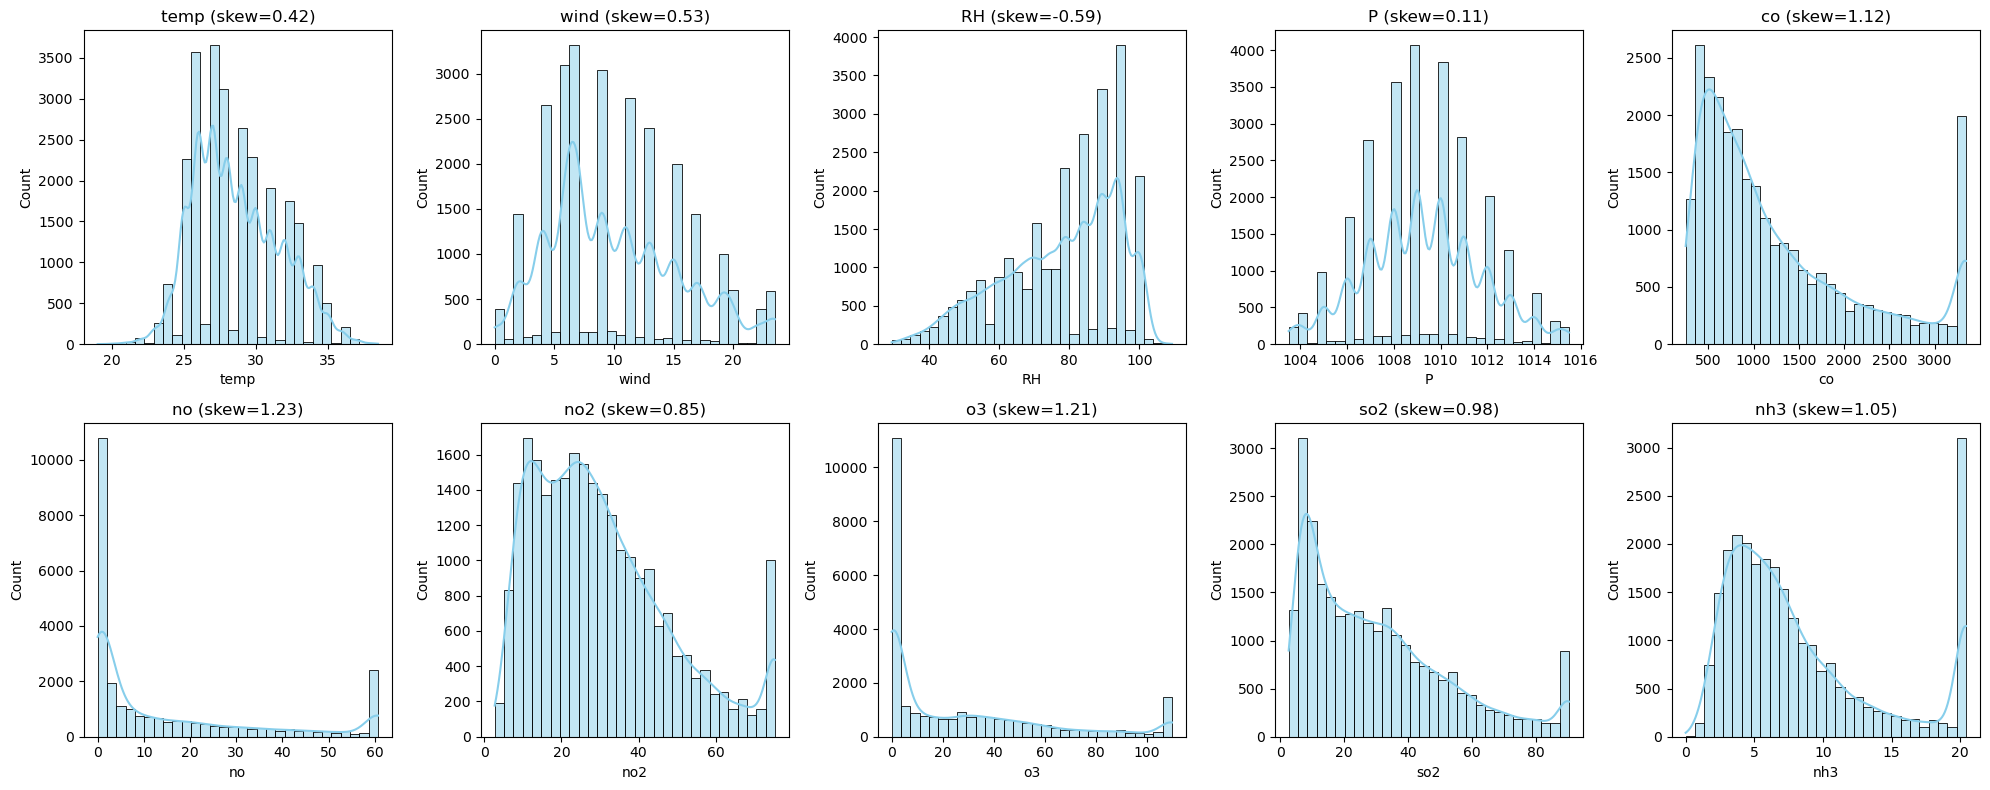

In [5]:
num_col = ["temp", "wind", "RH", "P", "co", "no", "no2", "o3", "so2", "nh3"]

fig, axs = plt.subplots(2, len(num_col)//2, figsize=(20, 8))  
axs = axs.flatten()  

for i, col in enumerate(num_col):
    sns.histplot(train[col], kde=True, bins=30, color='skyblue', ax=axs[i])
    skew_val = skew(train[col].dropna())
    axs[i].set_title(f'{col} (skew={skew_val:.2f})')
    axs[i].set_xlabel(col)
    axs[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

Ta thấy hầu hết các yếu tố hóa học đều bị lệch phải (skew > 1.5), ta sẽ apply log transform để đưa về gần phân phối chuẩn giúp các model dễ học hơn.

In [6]:
class ClearNegativeValue(BaseEstimator, TransformerMixin):
    def __init__(self, positive_col):
        self.positive_col = positive_col
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X, y=None):
        X = X.copy()  

        for col in self.positive_col:
            X.loc[X[col] < 0, col] = 0

        return X
    
class FixSkewedColumn(BaseEstimator, TransformerMixin):
    def __init__(self, skewed_col):
        self.skewed_col = skewed_col
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X, y=None):
        X = X.copy()  

        X[self.skewed_col] = X[self.skewed_col].apply(lambda x: np.log1p(x))
        return X
    
class RankEncodeFeature(BaseEstimator, TransformerMixin):
    def __init__(self, cat_col, target_col, time_col=None):
        self.cat_col = cat_col
        self.target_col = target_col
        self.time_col = time_col
        self.rank_maps = {}

    def fit(self, X, y=None):
        X = X.copy()

        for target in self.target_col:
            for cat in self.cat_col:
                mean_target = X.groupby(cat)[target].mean()
                rank_map = mean_target.rank().to_dict()
                new_col = f"{cat}_{target}"
                self.rank_maps[new_col] = rank_map

        return self

    def transform(self, X, y=None):
        X = X.copy()

        for target in self.target_col:
            for cat in self.cat_col:
                new_col = f"{cat}_{target}"
                mapped = X[cat].map(self.rank_maps.get(new_col, {}))
                rank_values = list(self.rank_maps.get(new_col, {}).values())
                if len(rank_values) > 0:
                    mode_val = pd.Series(rank_values).mode()[0]
                else:
                    mode_val = 0

                X[new_col] = mapped.fillna(mode_val)

        X = X.drop(columns=self.cat_col, errors="ignore")


        return X
    
class ExtractTime(BaseEstimator, TransformerMixin):
    def __init__(self, time_col):
        self.time_col = time_col
    
    def fit(self, X, y=None):
        return self  
    
    def transform(self, X, y=None):
        df = X.copy()
        
        time_series = pd.to_datetime(df[self.time_col], errors='coerce')
        df['year'] = time_series.dt.year
        df['month'] = time_series.dt.month
        df['day'] = time_series.dt.day
        df['dayofweek'] = time_series.dt.dayofweek
        df['hour'] = time_series.dt.hour
        
        if self.time_col in df.columns: 
            df = df.drop(columns=[self.time_col])

        return df
    
class MinMaxScalerDF(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols = cols
        self.scaler = MinMaxScaler()

    def fit(self, X, y=None):
        self.scaler.fit(X[self.cols])
        return self

    def transform(self, X, y=None):
        X = X.copy()
        X[self.cols] = self.scaler.transform(X[self.cols])
        return X

In [7]:
from sklearn.pipeline import Pipeline

time_col = "time"
num_col = ["temp", "wind", "RH", "P", "co", "no", "no2", "o3", "so2", "nh3"]
cat_col = ["weather"]
target_col = ["pm2_5_next1", "pm10_next1", "pm2_5_next2", "pm10_next2", "pm2_5_next3", "pm10_next3"]
skewed_col = ["co", "no", "no2", "o3", "so2", "nh3"]

full_fe_pipeline = Pipeline([
    ('clear_neg', ClearNegativeValue(positive_col=num_col)),
    ('fix_skew', FixSkewedColumn(skewed_col=skewed_col)),
    ('rank_encode', RankEncodeFeature(cat_col=cat_col, target_col=target_col, time_col=time_col)),
    ('extract_time', ExtractTime(time_col=time_col)),
    ('scaler', MinMaxScalerDF(cols=num_col))
])

In [8]:
full_fe_pipeline.fit(train)

Pipeline(steps=[('clear_neg',
                 ClearNegativeValue(positive_col=['temp', 'wind', 'RH', 'P',
                                                  'co', 'no', 'no2', 'o3',
                                                  'so2', 'nh3'])),
                ('fix_skew',
                 FixSkewedColumn(skewed_col=['co', 'no', 'no2', 'o3', 'so2',
                                             'nh3'])),
                ('rank_encode',
                 RankEncodeFeature(cat_col=['weather'],
                                   target_col=['pm2_5_next1', 'pm10_next1',
                                               'pm2_5_next2', 'pm10_next2',
                                               'pm2_5_next3', 'pm10_next3'],
                                   time_col='time')),
                ('extract_time', ExtractTime(time_col='time')),
                ('scaler',
                 MinMaxScalerDF(cols=['temp', 'wind', 'RH', 'P', 'co', 'no',
                                      'no2', 'o3', 'so2', 'nh3']))])

In [9]:
print(full_fe_pipeline["clear_neg"])

ClearNegativeValue(positive_col=['temp', 'wind', 'RH', 'P', 'co', 'no', 'no2',
                                 'o3', 'so2', 'nh3'])


In [10]:
train = full_fe_pipeline.transform(train)
val   = full_fe_pipeline.transform(val)
test  = full_fe_pipeline.transform(test)

d:\anaconda3\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


In [11]:
print(len(train), len(val), len(test))

26304 4344 4413


In [12]:
train

,temp,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3,weather_pm2_5_next1,weather_pm10_next1,weather_pm2_5_next2,weather_pm10_next2,weather_pm2_5_next3,weather_pm10_next3,year,month,day,dayofweek,hour
0,0.358974,0.170213,0.808343,0.541667,1.000000,1.000000,0.880066,0.0,1.000000,1.000000,279.26,321.64,280.09,316.42,267.37,299.51,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,0
1,0.358974,0.085106,0.808343,0.458333,1.000000,1.000000,0.900709,0.0,1.000000,1.000000,280.09,316.42,267.37,299.51,248.21,276.38,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,1
2,0.358974,0.085106,0.808343,0.458333,1.000000,1.000000,0.920135,0.0,1.000000,1.000000,267.37,299.51,248.21,276.38,228.91,254.06,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,2
3,0.358974,0.085106,0.808343,0.375000,1.000000,1.000000,0.941999,0.0,1.000000,1.000000,248.21,276.38,228.91,254.06,218.71,243.63,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,3
4,0.358974,0.000000,0.808343,0.458333,1.000000,1.000000,0.945532,0.0,1.000000,1.000000,228.91,254.06,218.71,243.63,212.32,238.87,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26299,0.307692,0.255319,0.808343,0.375000,0.980231,0.862279,1.000000,0.0,0.852745,0.856288,87.29,109.42,107.56,137.38,132.54,169.34,47.0,47.0,47.0,46.0,46.0,44.0,2024,8,31,5,19
26300,0.307692,0.255319,0.808343,0.458333,0.924469,0.868444,0.988042,0.0,0.836787,0.834769,107.56,137.38,132.54,169.34,153.58,194.11,47.0,47.0,47.0,46.0,46.0,44.0,2024,8,31,5,20
26301,0.326309,0.421940,0.785307,0.542133,0.967027,0.929575,0.920135,0.0,0.792861,0.890410,132.54,169.34,153.58,194.11,154.67,192.40,33.0,34.0,29.0,29.0,25.0,26.0,2024,8,31,5,21
26302,0.358974,0.468085,0.745785,0.458333,1.000000,0.982199,0.853498,0.0,0.789676,0.964973,153.58,194.11,154.67,192.40,145.65,180.12,33.0,34.0,29.0,29.0,25.0,26.0,2024,8,31,5,22


In [13]:
data_final = pd.concat([train, val, test], axis=0)
data_final

,temp,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3,weather_pm2_5_next1,weather_pm10_next1,weather_pm2_5_next2,weather_pm10_next2,weather_pm2_5_next3,weather_pm10_next3,year,month,day,dayofweek,hour
0,0.358974,0.170213,0.808343,0.541667,1.000000,1.000000,0.880066,0.000000,1.000000,1.000000,279.26,321.64,280.09,316.42,267.37,299.51,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,0
1,0.358974,0.085106,0.808343,0.458333,1.000000,1.000000,0.900709,0.000000,1.000000,1.000000,280.09,316.42,267.37,299.51,248.21,276.38,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,1
2,0.358974,0.085106,0.808343,0.458333,1.000000,1.000000,0.920135,0.000000,1.000000,1.000000,267.37,299.51,248.21,276.38,228.91,254.06,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,2
3,0.358974,0.085106,0.808343,0.375000,1.000000,1.000000,0.941999,0.000000,1.000000,1.000000,248.21,276.38,228.91,254.06,218.71,243.63,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,3
4,0.358974,0.000000,0.808343,0.458333,1.000000,1.000000,0.945532,0.000000,1.000000,1.000000,228.91,254.06,218.71,243.63,212.32,238.87,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35056,0.307692,0.723404,0.883413,0.125000,-0.174303,0.025317,-0.019374,0.676021,-0.241955,0.730877,1.43,2.06,1.41,2.23,1.63,2.68,17.0,17.0,18.0,18.0,21.0,21.0,2025,8,31,6,16
35057,0.358974,0.638298,0.883413,0.125000,-0.199120,0.011836,-0.011859,0.663788,-0.241955,0.724561,1.41,2.23,1.63,2.68,1.97,3.29,17.0,17.0,18.0,18.0,21.0,21.0,2025,8,31,6,17
35058,0.358974,0.382979,0.883413,0.208333,-0.196096,0.004804,0.014891,0.651006,-0.227246,0.766405,1.63,2.68,1.97,3.29,2.37,3.97,17.0,17.0,18.0,18.0,21.0,21.0,2025,8,31,6,18
35059,0.358974,0.255319,0.883413,0.208333,-0.182572,0.002414,0.036438,0.640237,-0.216657,0.794748,1.97,3.29,2.37,3.97,2.75,4.66,17.0,17.0,18.0,18.0,21.0,21.0,2025,8,31,6,19


In [17]:
import joblib
joblib.dump(full_fe_pipeline, "full_featureengineer_pipeline_duy.pkl")
data_final.to_csv("../Data_Final_duy.csv", index=False)

In [15]:
scaler_step = full_fe_pipeline.named_steps['scaler']
scaler = scaler_step.scaler
cols = scaler_step.cols

print(f"{'Feature':<10} {'Min':>10} {'Max':>10} {'Data_min':>12} {'Data_max':>12} {'Range':>10} {'Scale':>10}")

for i, col in enumerate(cols):
    print(f"{col:<10} "
          f"{scaler.feature_range[0]:>10.2f} "
          f"{scaler.feature_range[1]:>10.2f} "
          f"{scaler.data_min_[i]:>12.4f} "
          f"{scaler.data_max_[i]:>12.4f} "
          f"{scaler.data_range_[i]:>10.4f} "
          f"{scaler.scale_[i]:>10.4f}")

Feature           Min        Max     Data_min     Data_max      Range      Scale
temp             0.00       1.00      19.0000      38.5000    19.5000     0.0513
wind             0.00       1.00       0.0000      23.5000    23.5000     0.0426
RH               0.00       1.00      29.3924     109.3183    79.9259     0.0125
P                0.00       1.00    1003.5000    1015.5000    12.0000     0.0833
co               0.00       1.00       5.5268       8.1154     2.5886     0.3863
no               0.00       1.00       0.0000       4.1222     4.1222     0.2426
no2              0.00       1.00       1.3029       4.3357     3.0328     0.3297
o3               0.00       1.00       0.0000       4.7085     4.7085     0.2124
so2              0.00       1.00       1.2782       4.5162     3.2380     0.3088
nh3              0.00       1.00       0.0000       3.0643     3.0643     0.3263
